# Klasifikasi Binary: lie, titanic_mini, dan binary_classification

Di notebook ini terdapat tiga dataset yang masuk kategori binary:  `lie_dataset_100`,  `titanic_mini`, dan `binary_classification`. Yang mau dijawab: targetnya apa, apakah betul-betul binary, dan dari ketiganya mana yang paling pas mewakili kategori ini.

Definisinya sederhana: satu kolom target dengan tepat dua kelas.


In [1]:
import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# nomor arsip -> nama file CSV di dalam zip
SOURCES = {
    "A4 lie":     (4, "lie_dataset_100.csv"),
    "A5 titanic": (5, "titanic_mini.csv"),
    "A6 binary":  (6, "binary_classification.csv"),
}
BIN = {"A4 lie": "lie", "A5 titanic": "Survived", "A6 binary": "target"}

SEED = 42
# Folder tempat file zip berada. Bisa diubah, atau set environment variable DATA_DIR.
DATA_DIR = os.environ.get("DATA_DIR", ".")

def find_zip(n):
    # cocok dengan 'archive (4).zip', 'archive__4_.zip', dst., tapi tidak 'archive (14).zip'
    pat = re.compile(rf"archive\D*{n}\D*\.zip$", re.I)
    for f in sorted(os.listdir(DATA_DIR)):
        if pat.search(f):
            return os.path.join(DATA_DIR, f)
    raise FileNotFoundError(f"Zip arsip {n} tidak ditemukan di DATA_DIR={DATA_DIR!r}")

def read_from_zip(n, member):
    with zipfile.ZipFile(find_zip(n)) as z:
        with z.open(member) as f:
            return pd.read_csv(f)

data = {k: read_from_zip(n, m) for k, (n, m) in SOURCES.items()}
print({k: v.shape for k, v in data.items()})

{'A4 lie': (100, 5), 'A5 titanic': (891, 4), 'A6 binary': (400, 4)}


## 1. Gambaran umum data

In [2]:
rows = []
for k, df in data.items():
    rows.append({"Dataset": k, "Baris": df.shape[0], "Kolom": df.shape[1],
                 "Nilai kosong": int(df.isna().sum().sum()), "Baris duplikat": int(df.duplicated().sum())})
pd.DataFrame(rows).set_index("Dataset")

,Baris,Kolom,Nilai kosong,Baris duplikat
Dataset,,,,
A4 lie,100,5,0,0
A5 titanic,891,4,0,876
A6 binary,400,4,0,0


Titanic punya 876 baris duplikat dari 891. Kedengarannya aneh, tapi wajar: fiturnya cuma tiga kolom 0/1, jadi banyak penumpang kebetulan punya kombinasi fitur yang sama. Ini dibahas lagi di bagian 3.

## 2. Target dan distribusi kelas

Target ketiganya satu kolom dengan dua nilai: `lie` (A4), `Survived` (A5), dan `target` (A6). Kita lihat dulu seberapa seimbang kelasnya.

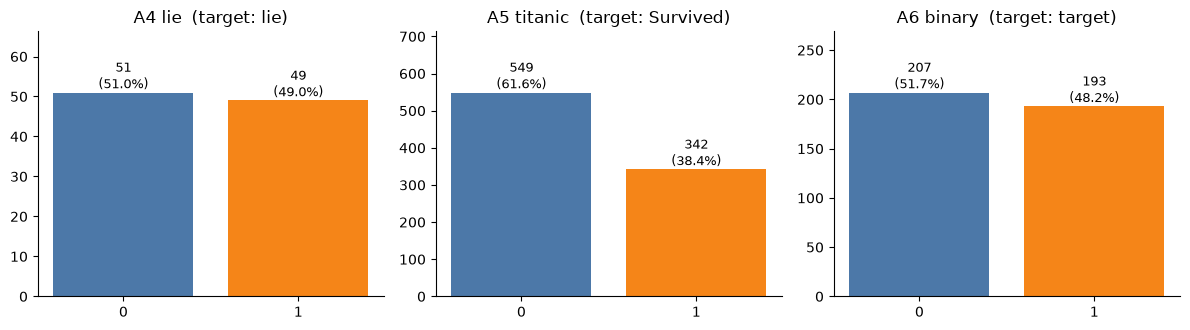

A4 lie -> jumlah kelas: 2 | nilai: [0, 1]
A5 titanic -> jumlah kelas: 2 | nilai: [0, 1]
A6 binary -> jumlah kelas: 2 | nilai: [0, 1]


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (k, t) in zip(axs, BIN.items()):
    vc = data[k][t].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=["#4C78A8", "#F58518"])
    ax.set_title(f"{k}  (target: {t})")
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v}\n({v/vc.sum():.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, vc.max() * 1.3)
plt.tight_layout(); plt.show()

for k, t in BIN.items():
    print(k, "-> jumlah kelas:", data[k][t].nunique(), "| nilai:", sorted(data[k][t].unique().tolist()))

## 3. Titanic: kenapa hasilnya cepat mentok?

Fitur Titanic di sini cuma `Sex`, `Children`, dan `FirstClass`, semuanya 0/1, jadi hanya ada 8 kombinasi fitur. Kalau dalam satu kombinasi ada penumpang yang selamat dan ada yang tidak, model sebagus apa pun tidak bisa membedakannya. Jadi aku hitung akurasi tertinggi yang masih mungkin dicapai, yaitu kalau tiap kombinasi selalu ditebak dengan label mayoritasnya.

In [4]:
t = data["A5 titanic"]
g = t.groupby(["Sex", "Children", "FirstClass"]).Survived.agg(jumlah="count", rasio_selamat="mean")
display(g.round(3))

batas = t.groupby(["Sex", "Children", "FirstClass"]).Survived.agg(lambda s: max(s.mean(), 1 - s.mean()) * len(s)).sum() / len(t)
print(f"Jumlah pola fitur unik         : {len(g)}")
print(f"Akurasi maksimum teoritis      : {batas:.3f}")
print(f"Akurasi menebak kelas mayoritas: {t.Survived.value_counts(normalize=True).max():.3f}")
print("Rasio selamat per Sex (0=laki-laki, 1=perempuan):", t.groupby('Sex').Survived.mean().round(3).to_dict())

jumlah  rasio_selamat
Sex Children FirstClass                       
0   0        0              418          0.110
             1              119          0.353
    1        0               37          0.486
             1                3          1.000
1   0        0              180          0.644
             1               91          0.978
    1        0               40          0.650
             1                3          0.667

Jumlah pola fitur unik         : 8
Akurasi maksimum teoritis      : 0.790
Akurasi menebak kelas mayoritas: 0.616
Rasio selamat per Sex (0=laki-laki, 1=perempuan): {0: 0.189, 1: 0.742}


## 4. Baseline model

Untuk gambaran kasar aku coba Logistic Regression dan Random Forest dengan 5-fold stratified cross-validation.

In [5]:
def cv_binary(key):
    df, tcol = data[key], BIN[key]
    X = df.drop(columns=[tcol] + (["split"] if "split" in df.columns else []))
    y = df[tcol]
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    models = {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
              "RandomForest": RandomForestClassifier(200, random_state=SEED, n_jobs=-1)}
    out = []
    for name, m in models.items():
        r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
        out.append({"Dataset": key, "Model": name,
                    "Majority acc": y.value_counts(normalize=True).max(),
                    "Accuracy": r["test_accuracy"].mean(), "Std acc": r["test_accuracy"].std(),
                    "F1": r["test_f1"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
    return out

res_bin = pd.DataFrame([r for k in BIN for r in cv_binary(k)]).set_index(["Dataset", "Model"])
res_bin.round(3)

Majority acc  Accuracy  Std acc     F1  ROC-AUC
Dataset    Model                                                        
A4 lie     LogReg               0.510     0.990    0.020  0.989    1.000
           RandomForest         0.510     0.980    0.024  0.979    0.998
A5 titanic LogReg               0.616     0.790    0.018  0.716    0.836
           RandomForest         0.616     0.788    0.018  0.716    0.835
A6 binary  LogReg               0.518     0.893    0.017  0.889    0.961
           RandomForest         0.518     0.872    0.017  0.868    0.951

Dari hasilnya:

- **A4 lie**: akurasi sekitar 0,99 dengan model sederhana. Datanya cuma 100 baris dan fiturnya berkorelasi kuat dengan target, jadi terlalu mudah dan hasilnya gampang goyah.
- **A5 titanic**: model mentok di sekitar 0,79, persis di batas teoretis tadi. Random Forest tidak lebih baik dari Logistic Regression, dan masalahnya ada di fitur, bukan di modelnya.
- **A6 binary**: akurasinya di tengah-tengah dan kedua model masih kelihatan bedanya, jadi dataset ini masih berguna untuk membandingkan model.

## 5. Apakah benar-benar binary?

In [6]:
verif = pd.DataFrame({
    k: {"Kolom target": BIN[k], "Jumlah kelas": data[k][BIN[k]].nunique(),
        "Nilai kelas": sorted(data[k][BIN[k]].unique().tolist()),
        "Lolos (tepat 2 kelas)": data[k][BIN[k]].nunique() == 2}
    for k in BIN}).T
verif

,Kolom target,Jumlah kelas,Nilai kelas,Lolos (tepat 2 kelas)
A4 lie,lie,2,"[0, 1]",True
A5 titanic,Survived,2,"[0, 1]",True
A6 binary,target,2,"[0, 1]",True


Ketiganya lolos: satu kolom target, dua kelas. Bedanya ada di kualitas dan ukuran datanya, dan itu yang jadi dasar skorku.

| Dataset | Skor | Alasan |
|---|---|---|
| A4 lie | 4 | Binary murni dan seimbang, tapi cuma 100 baris dan hampir terpisah sempurna, kemungkinan data sintetis. |
| A5 titanic | 4 | Binary alami dengan data nyata dan kelas yang agak timpang (realistis). Tapi fiturnya cuma 8 pola, jadi akurasi maksimumnya terbatas di sekitar 79%. |
| A6 binary | 5 | Struktur binary paling bersih, hampir seimbang, ukurannya cukup, dan sudah ada kolom `split`. Kurangnya: fiturnya anonim dan sintetis. |

In [7]:
SKOR = {"A4 lie": 4, "A5 titanic": 4, "A6 binary": 5}

def n_features(k):
    df = data[k]; return df.shape[1] - 1 - (1 if "split" in df.columns else 0)

vc = {k: data[k][BIN[k]].value_counts() for k in BIN}
summary = pd.DataFrame({
    "Sampel": {k: len(data[k]) for k in BIN},
    "Fitur input": {k: n_features(k) for k in BIN},
    "Imbalance (max/min)": {k: round(vc[k].max() / vc[k].min(), 2) for k in BIN},
    "F1 (LogReg)": {k: round(res_bin.loc[(k, "LogReg"), "F1"], 3) for k in BIN},
    "ROC-AUC (LogReg)": {k: round(res_bin.loc[(k, "LogReg"), "ROC-AUC"], 3) for k in BIN},
    "Skor kesesuaian": SKOR,
})
summary

,Sampel,Fitur input,Imbalance (max/min),F1 (LogReg),ROC-AUC (LogReg),Skor kesesuaian
A4 lie,100,4,1.04,0.989,1.000,4
A5 titanic,891,3,1.61,0.716,0.836,4
A6 binary,400,2,1.07,0.889,0.961,5


## 6. Kesimpulan

Yang paling pas mewakili binary menurutku adalah **A6 `binary_classification`**. Strukturnya paling bersih, kelasnya hampir seimbang, ukurannya cukup, dan hasilnya tidak segampang A4 maupun semandek A5.

A5 titanic tetap berguna sebagai pelengkap karena datanya nyata dan kelasnya agak timpang, tapi sulit dipakai untuk membandingkan model. A4 terlalu kecil dan terlalu mudah.

Soal pemodelan: kalau pakai neural network, binary biasanya memakai satu output sigmoid dengan binary cross-entropy. Untuk metrik, jangan cuma accuracy, apalagi di data yang agak timpang seperti Titanic. F1 dan ROC-AUC lebih jujur.